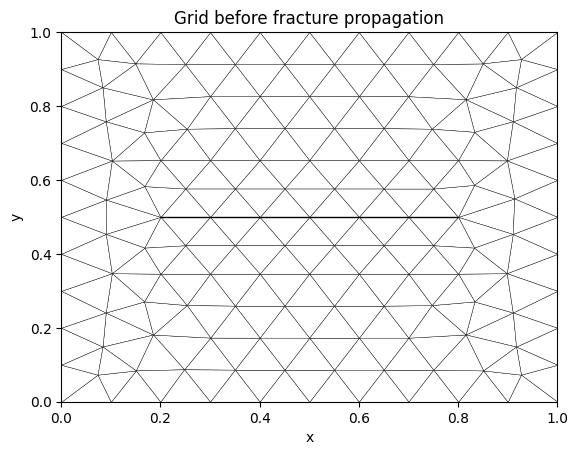

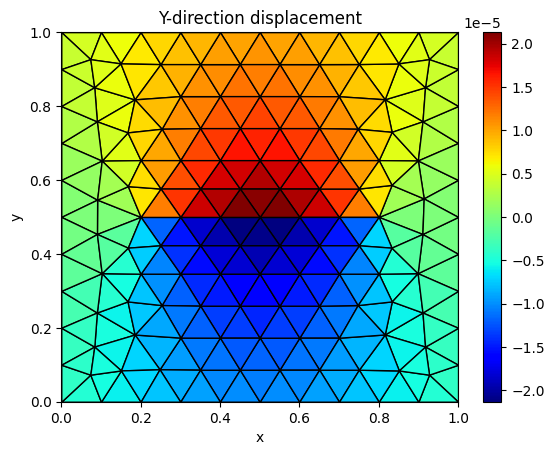

Grid Tensor grid in 1 dimensions.
Number of cells 6
Number of faces 7
Number of nodes 7
 has no 'u' defined in TIME_STEP_SOLUTIONS
Displacement jump n value:  [3.83724930e-05 3.83834879e-05]
Displacement jump n r:  [0.15 0.15]
Displacement jump t value:  [ 1.72312493e-10 -1.50939371e-09]
Displacement jump t r:  [0.15 0.15]


In [16]:
"""
Evaluate the singularity order (exponent) and stress intensity factor (SIF) 
at fracture tips within a simulation domain for Sneddon's problem.

Currently, the script only supports a single fracture with two fracture tips.

Features: 
 - Provide several options for selecting evaluation locations (cell centers) along the fracture. 
   Singularity order (exponent): 
        Single-scale option: evaluate singularity at the same grid refinement level by two cell centers (i and j)
        near the fracture tip. The cell center i is selected at the fracture tip cell (r_i=h/2). The cell center j can 
        be movable to the third cell closest to the frature tip (r_j=5*h/2). 

        Two-scale option: cell centers i and j, whose distance are r_i and r_j, are movable and selected from fine and 
        coarse grids, respectively. If the refinement levels of coarse and fine grids are k_c and k_f, where k_f=k_c+1, 
        the distance from cell center j to the fracture tip face in coarse grids is (4*k_c+1)*h_c/2 and the distance from 
        cell center j in fine grids is (4*k_f+1)*h_f/2. 
    
    Stress intensity factor (SIF) KI: 
        Single-scale option: 
            Option 1: The location is selected on the third cell closest to the frature tip (r_j=5*h/2). 
            The singularity order is set as 0.5.
            Option 2: The location is the same as Option 1, but the singularity order is from the single-scale option.
            Option 3: The location is selected on cell center j from the two-scale option. The singularity order is also 
            from the two-scale option. 

        Two-scale option: the expression is derived from theoretical solution with elimination of the second term. 

 - Perform both single-scale and two-scale convergence analysis. 
   The single-scale analysis evaluates convergence only with respect to mesh size (cell size: h),
   while the two-scale analysis involves coarse and fine models.

"""

import porepy as pp
import numpy as np

import math
import matplotlib.pyplot as plt
import scipy.sparse as sps

from tests.functional.setups.manu_sneddon_2d import ManuSneddonModel2d

a = 0.3
poi = 0.25
shear_modulus = 1.0
lam = 2 * shear_modulus * poi / (1 - 2 * poi)

params = {
    "prepare_simulation": True,
    "material_constants": {"solid": pp.SolidConstants(shear_modulus=shear_modulus, lame_lambda=lam)},
    "a": a,
    "domain_size": 1.0,
    "p0": 1e-4,
    "poi": poi,
    "meshing_arguments": {"cell_size": 0.1},
    "grid_type": "simplex",
    "theta_rad": math.radians(90 - 0),
    "num_bem_segments": 1000,
    "error_exclusion_zone_fracture_tips": 0.1,
}

# Chose the sampling option for fracture cells 
# params.update({
#     "sampling": {"mode": "refinement", "level": 1}
# })

params.update({
    "sampling": {"mode": "fixed", "steps": 1}
})

model = ManuSneddonModel2d(params=params)
pp.run_time_dependent_model(model)

# Plot
pp.plot_grid(
    model.mdg,
    rgb=[1, 1, 1],
    figsize=(8,8), 
    plot_2d=True,           
    linewidth=0.3,
    alpha=1.0,
    title="Grid before fracture propagation"
)
plt.show()

# 2D displacement plot
for g, data in model.mdg.subdomains(return_data=True):
    # get 'u'（t=0 by default）
    u = data.get(pp.TIME_STEP_SOLUTIONS, {}).get("u", {}).get(0, None)

    if u is not None:
        # get the displacement y along the y direction
        y_disp = u[1::2]

        # plot
        pp.plot_grid(
            g,
            cell_value=y_disp,
            plot_2d=True,
            title="Y-direction displacement"
        )
        plt.show()
    else:
        print(f"Grid {g} has no 'u' defined in TIME_STEP_SOLUTIONS")

# Fracture tip singularity convergence analysis
# Only valid for one single fracture
class FractureDisplacementJump: 
    # This class only can be done after having a mdg provided by the Model class (ManuSneddonModel2d here)
    def __init__(self, model):
        self.model = model
        self.mdg = model.mdg
        self.equation_system = model.equation_system

        self.sd_frac = self.mdg.subdomains(dim=1)[0]
        self.tip_faces = self.sd_frac.tags["tip_faces"].nonzero()[0]                 
        _, self.tip_cells = self.sd_frac.signs_and_cells_of_boundary_faces(self.tip_faces)  
        self.tip_face_centers = self.sd_frac.face_centers[:, self.tip_faces] 

        self.params = model.params
    
    def normal_displacement_jump(self):
        sd_frac = self.sd_frac
        u_jump = self.model.displacement_jump([sd_frac])                     
        normal_op = self.model.normal_component([sd_frac]) 
        u_jump_whole_frac = (normal_op @ u_jump).value(self.equation_system)
        return u_jump_whole_frac
    
    def tangential_displacement_jump(self):
        sd_frac = self.sd_frac
        u_jump = self.model.displacement_jump([sd_frac])                     
        tangential_op = self.model.tangential_component([sd_frac]) 
        u_jump_whole_frac = (tangential_op @ u_jump).value(self.equation_system)
        return u_jump_whole_frac

    def sampling_frac_cell(self):
        sampling_cfg = self.params.get("sampling", {})
        step_mode = sampling_cfg.get("mode", None)

        if step_mode is None:
            raise ValueError("Sampling mode should be defined: 'refinement' or 'fixed'. ")    

        if step_mode == "refinement":
            refinement_level = sampling_cfg.get("level", None)
            if refinement_level is None:
                raise ValueError("mode='refinement': keywords 'level' should be defined.")
            n_steps = 2 * refinement_level
        elif step_mode == "fixed": 
            n_steps_fixed = sampling_cfg.get("steps", None)
            if n_steps_fixed is None:
                raise ValueError("mode='fixed': 'steps' should be defined. ")
            n_steps = n_steps_fixed
        else: 
            raise ValueError(f"Unknown step_mode='{step_mode}'")
 
        current_frac_cells = np.where(self.tip_cells == 0, n_steps, self.tip_cells - n_steps)
        return current_frac_cells
    
    def extract_sampling_normal_jump(self):
        sd_frac = self.sd_frac
        current_frac_cells = self.sampling_frac_cell()
        r_cell_to_tip = np.linalg.norm(
            self.tip_face_centers - sd_frac.cell_centers[:, current_frac_cells], axis=0
        )
        u_jump = self.normal_displacement_jump()[current_frac_cells]
        return u_jump, r_cell_to_tip, tip_face_centers
    
    def extract_sampling_tangential_jump(self):
        sd_frac = self.sd_frac
        current_frac_cells = self.sampling_frac_cell()
        r_cell_to_tip = np.linalg.norm(
            self.tip_face_centers - sd_frac.cell_centers[:, current_frac_cells], axis=0
        )
        u_jump = self.tangential_displacement_jump()[current_frac_cells]
        return u_jump, r_cell_to_tip, tip_face_centers


sneddon = FractureDisplacementJump(model)

# cod_n_coarse, r_n_coarse, tip_face_coarse = extract_displacement_jump(model_coarse, k_target_coarse)
u_jump_n, r_n, tip_face_centers = sneddon.extract_sampling_normal_jump()
# print("tip_face_centers: ", tip_face_centers)
u_jump_t, r_t, tip_face_centers = sneddon.extract_sampling_tangential_jump()
# print("tip_face_centers: ", tip_face_centers)

print("Displacement jump n value: ", u_jump_n)
print("Displacement jump n r: ", r_n)

print("Displacement jump t value: ", u_jump_t)
print("Displacement jump t r: ", r_t)
